# Text Classification


In [1]:
from sklearn.datasets import fetch_20newsgroups

categories = ["alt.atheism", "soc.religion.christian", "comp.graphics", "sci.med"]

twenty_train = fetch_20newsgroups(
    subset="train", categories=categories, shuffle=True, random_state=42
)

In [2]:
twenty_train.target_names

['alt.atheism', 'comp.graphics', 'sci.med', 'soc.religion.christian']

In [3]:
print(twenty_train.DESCR)

.. _20newsgroups_dataset:

The 20 newsgroups text dataset
------------------------------

The 20 newsgroups dataset comprises around 18000 newsgroups posts on
20 topics split in two subsets: one for training (or development)
and the other one for testing (or for performance evaluation). The split
between the train and test set is based upon a messages posted before
and after a specific date.

This module contains two loaders. The first one,
:func:`sklearn.datasets.fetch_20newsgroups`,
returns a list of the raw texts that can be fed to text feature
extractors such as :class:`~sklearn.feature_extraction.text.CountVectorizer`
with custom parameters so as to extract feature vectors.
The second one, :func:`sklearn.datasets.fetch_20newsgroups_vectorized`,
returns ready-to-use features, i.e., it is not necessary to use a feature
extractor.

**Data Set Characteristics:**

=================   ==========
Classes                     20
Samples total            18846
Dimensionality               1

In [4]:
print(len(twenty_train.data))
print(len(twenty_train.filenames))

2257
2257


In [5]:
print("\n".join(twenty_train.data[0].split("\n")[:3]))

From: sd345@city.ac.uk (Michael Collier)
Subject: Converting images to HP LaserJet III?
Nntp-Posting-Host: hampton


In [6]:
twenty_train.target_names[twenty_train.target[0]]

'comp.graphics'

## Bag of Words


In [7]:
# tokenizing and filtering of stopwords are all included in CountVectorizer,
# which builds a dictionary of features and transforms documents to feature vectors
from sklearn.feature_extraction.text import CountVectorizer

count_vect = CountVectorizer()
X_train_counts = count_vect.fit_transform(twenty_train.data)
X_train_counts.shape

(2257, 35788)

In [8]:
len(count_vect.vocabulary_)

35788

In [9]:
count_vect.vocabulary_.get("algorithm")

4690

## TF-IDF (Term Frequency–Inverse Document Frequency)

TF-IDF is a numerical statistic used to measure how important a word is to a document relative to a collection of documents (corpus).

The TF-IDF score is calculated using the following formula:

$$
\text{TF-IDF}(t,d,D) = \text{TF}(t,d) \times \text{IDF}(t,D)
$$

**Where:**

- **t** = A specific term (word)
- **d** = A single document
- **D** = The entire collection of documents (corpus)

---

**Step 1: Term Frequency (TF)**

Term Frequency measures how often a term appears in a specific document.

_Formula_

$$
\text{TF}(t,d) =
\frac{\text{Number of times term } t \text{ appears in document } d}
{\text{Total number of terms in document } d}
$$

**Explanation**

- A higher TF value indicates that the term appears frequently in the document.
- A lower TF value indicates that the term appears less frequently in the document.

**_Note:_** Other TF variants use raw counts, binary values, or logarithmic scaling.

For example, logarithmic scaling can be calculated as:

$$
\text{TF}(t,d) = \log\left(1 + \text{freq}(t,d)\right)
$$

---

**Step 2: Inverse Document Frequency (IDF)**

Inverse Document Frequency measures how common or rare a term is across the entire corpus.

- **Common words**, such as "the" and "is", generally receive lower IDF scores.
- **Rare words** receive higher IDF scores because they can help distinguish one document from another.

_Formula_

$$
\text{IDF}(t,D) = \log\left(\frac{N}{\text{DF}(t)}\right)
$$

**Where:**

- **N** = Total number of documents in the corpus, denoted by $|D|$.
- **DF(t)** = Number of documents containing the term $t$.

**Explanation**

- If a term appears in every document, its IDF score is $0$ under this formula.
- If a term appears in only a few documents, its IDF score is higher.
- The logarithm helps control the scale of the IDF values.

---

**Step 3: Calculate the TF-IDF Score**

The final TF-IDF score is the product of Term Frequency and Inverse Document Frequency.

_Formula_

$$
\boxed{
\text{TF-IDF}(t,d,D) =
\text{TF}(t,d) \times
\log\left(\frac{N}{\text{DF}(t)}\right)
}
$$

A **high TF-IDF score** indicates that a term appears frequently in a particular document but is relatively uncommon across the entire corpus.

A **low TF-IDF score** indicates that a term is either infrequent in the document or common across the corpus.


In [10]:
from sklearn.feature_extraction.text import TfidfTransformer

tfidf = TfidfTransformer()
X_train_tfidf = tfidf.fit_transform(X_train_counts)
X_train_tfidf.shape

(2257, 35788)

In [11]:
from sklearn.naive_bayes import MultinomialNB

clf = MultinomialNB()
clf.fit(X_train_tfidf, twenty_train.target)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](4,)","[480.,584.,594.,599.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](4,)","[-1.55,-1.35,-1.33,-1.33]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[0,1,2,3]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](4, 35788)","[[0.11,1.68,0. ,...,0. ,0. ,0. ], [1.24,0.66,0. ,...,0. ,0.11,0. ], [0.99,0.8 ,0.01,...,0.21,0. ,0.12], [2.34,0.14,0. ,...,0. ,0. ,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](4, 35788)","[[-10.51, -9.62,-10.61,...,-10.61,-10.61,-10.61], [ -9.8 ,-10.1 ,-10.6 ,...,-10.6 ,-10.5 ,-10.6 ], [ -9.94,-10.04,-10.62,...,-10.44,-10.63,-10.52], [ -9.44,-10.52,-10.65,...,-10.65,-10.65,-10.65]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,35788


In [12]:
docs_new = ["God is love", "OpenGL on the GPU is fast"]
X_new_counts = count_vect.transform(docs_new)
X_new_tfidf = tfidf.transform(X_new_counts)

predicted = clf.predict(X_new_tfidf)

for doc, category in zip(docs_new, predicted):
    print("%r => %s" % (doc, twenty_train.target_names[category]))

'God is love' => soc.religion.christian
'OpenGL on the GPU is fast' => comp.graphics


## Pipeline


In [13]:
from sklearn.pipeline import Pipeline

text_clf = Pipeline(
    [
        ("vect", CountVectorizer()),
        ("tfidf", TfidfTransformer()),
        ("clf", MultinomialNB()),
    ]
)

text_clf.fit(twenty_train.data, twenty_train.target)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vect', ...), ('tfidf', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


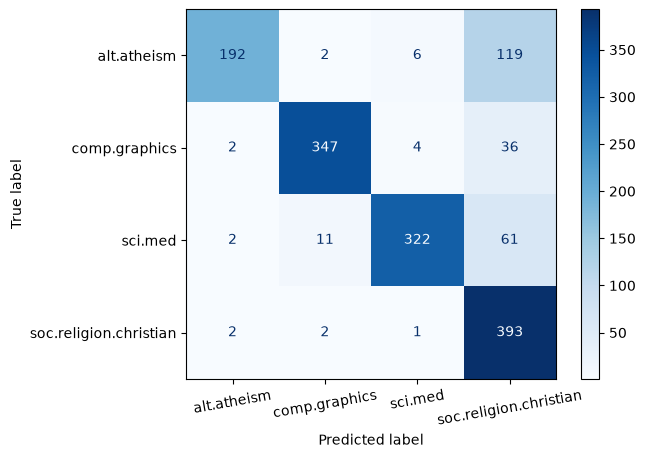

              precision    recall  f1-score   support

           0       0.97      0.60      0.74       319
           1       0.96      0.89      0.92       389
           2       0.97      0.81      0.88       396
           3       0.65      0.99      0.78       398

    accuracy                           0.83      1502
   macro avg       0.89      0.82      0.83      1502
weighted avg       0.88      0.83      0.84      1502



In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

twenty_test = fetch_20newsgroups(
    subset="test", categories=categories, shuffle=True, random_state=42
)
docs_test = twenty_test.data
predicted = text_clf.predict(docs_test)

cm = confusion_matrix(
    twenty_test.target,
    predicted,
)
ConfusionMatrixDisplay(cm, display_labels=twenty_test.target_names).plot(
    cmap="Blues", xticks_rotation=10
)
plt.show()
print(classification_report(twenty_test.target, predicted))

In [15]:
from sklearn.model_selection import GridSearchCV

parameters = {
    "vect__ngram_range": [(1, 1), (1, 2)],
    "tfidf__use_idf": (True, False),
    "clf__alpha": (1e-2, 1e-3),
}
gs_clf = GridSearchCV(text_clf, parameters, cv=5, n_jobs=-1)
gs_clf.fit(twenty_train.data, twenty_train.target)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...inomialNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__alpha': (0.01, ...), 'tfidf__use_idf': (True, ...), 'vect__ngram_range': [(1, ...), (1, ...)]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defaul

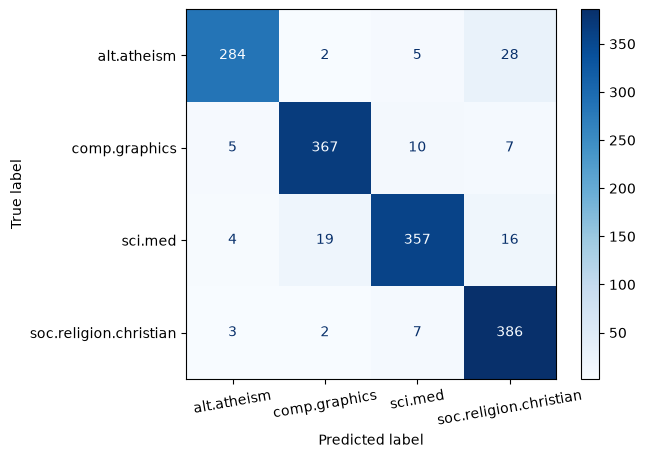

              precision    recall  f1-score   support

           0       0.96      0.89      0.92       319
           1       0.94      0.94      0.94       389
           2       0.94      0.90      0.92       396
           3       0.88      0.97      0.92       398

    accuracy                           0.93      1502
   macro avg       0.93      0.93      0.93      1502
weighted avg       0.93      0.93      0.93      1502



In [16]:
predicted = gs_clf.predict(docs_test)

cm = confusion_matrix(
    twenty_test.target,
    predicted,
)
ConfusionMatrixDisplay(cm, display_labels=twenty_test.target_names).plot(
    cmap="Blues", xticks_rotation=10
)
plt.show()
print(classification_report(twenty_test.target, predicted))

In [17]:
from sklearn.svm import SVC

text_clf_svc = Pipeline(
    [
        ("vect", CountVectorizer()),
        ("tfidf", TfidfTransformer()),
        ("clf", SVC()),
    ]
)

text_clf_svc.fit(twenty_train.data, twenty_train.target)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vect', ...), ('tfidf', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


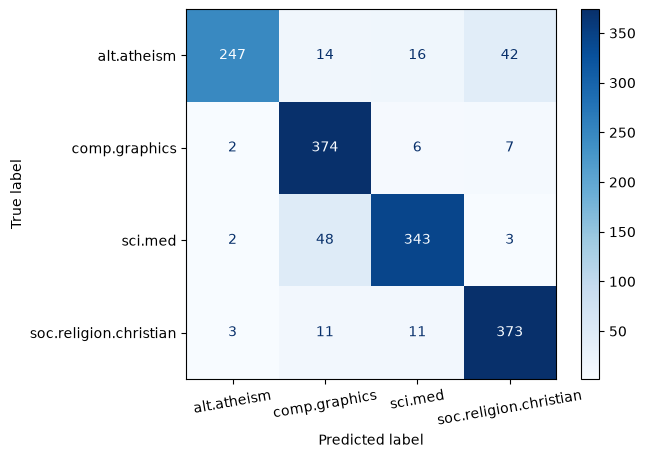

              precision    recall  f1-score   support

           0       0.97      0.77      0.86       319
           1       0.84      0.96      0.89       389
           2       0.91      0.87      0.89       396
           3       0.88      0.94      0.91       398

    accuracy                           0.89      1502
   macro avg       0.90      0.88      0.89      1502
weighted avg       0.90      0.89      0.89      1502



In [18]:
predicted = text_clf_svc.predict(docs_test)

cm = confusion_matrix(
    twenty_test.target,
    predicted,
)
ConfusionMatrixDisplay(cm, display_labels=twenty_test.target_names).plot(
    cmap="Blues", xticks_rotation=10
)
plt.show()
print(classification_report(twenty_test.target, predicted))

# Topic Modelling


In [19]:
# Creating example documents
doc_1 = "A whopping 96.5 percent of water on Earth is in our oceans, covering 71 percent of the surface of our planet. And at any given time, about 0.001 percent is floating above us in the atmosphere. If all of that water fell as rain at once, the whole planet would get about 1 inch of rain."

doc_2 = "One-third of your life is spent sleeping. Sleeping 7-9 hours each night should help your body heal itself, activate the immune system, and give your heart a break. Beyond that--sleep experts are still trying to learn more about what happens once we fall asleep."

doc_3 = "A newborn baby is 78 percent water. Adults are 55-60 percent water. Water is involved in just about everything our body does."

doc_4 = "While still in high school, a student went 264.4 hours without sleep, for which he won first place in the 10th Annual Great San Diego Science Fair in 1964."

doc_5 = "We experience water in all three states: solid ice, liquid water, and gas water vapor."

# Create corpus
corpus = [doc_1, doc_2, doc_3, doc_4, doc_5]

## Preprocessing


In [20]:
import string
import nltk

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
from nltk.corpus import stopwords
from nltk.stem.wordnet import WordNetLemmatizer

stop = set(stopwords.words("english"))
puncs = set(string.punctuation)
lemma = WordNetLemmatizer()


def clean(doc):
    punc_free = "".join(ch for ch in doc if ch not in puncs)
    return [
        lemma.lemmatize(word) for word in punc_free.lower().split() if word not in stop
    ]


clean_corpus = [clean(doc) for doc in corpus]

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [21]:
print(clean_corpus[:5])

[['whopping', '965', 'percent', 'water', 'earth', 'ocean', 'covering', '71', 'percent', 'surface', 'planet', 'given', 'time', '0001', 'percent', 'floating', 'u', 'atmosphere', 'water', 'fell', 'rain', 'whole', 'planet', 'would', 'get', '1', 'inch', 'rain'], ['onethird', 'life', 'spent', 'sleeping', 'sleeping', '79', 'hour', 'night', 'help', 'body', 'heal', 'activate', 'immune', 'system', 'give', 'heart', 'break', 'beyond', 'thatsleep', 'expert', 'still', 'trying', 'learn', 'happens', 'fall', 'asleep'], ['newborn', 'baby', '78', 'percent', 'water', 'adult', '5560', 'percent', 'water', 'water', 'involved', 'everything', 'body'], ['still', 'high', 'school', 'student', 'went', '2644', 'hour', 'without', 'sleep', 'first', 'place', '10th', 'annual', 'great', 'san', 'diego', 'science', 'fair', '1964'], ['experience', 'water', 'three', 'state', 'solid', 'ice', 'liquid', 'water', 'gas', 'water', 'vapor']]


## TDM - Term Document Matrix


In [22]:
from gensim import corpora

dictionary = corpora.Dictionary(clean_corpus)
tdm = [dictionary.doc2bow(doc) for doc in clean_corpus]

In [23]:
from gensim.models import LdaModel

lda = LdaModel(tdm, num_topics=3, id2word=dictionary)
lda.print_topics()

[(0,
  '0.037*"sleeping" + 0.024*"still" + 0.024*"hour" + 0.023*"learn" + 0.022*"activate" + 0.022*"spent" + 0.022*"beyond" + 0.022*"thatsleep" + 0.022*"break" + 0.022*"happens"'),
 (1,
  '0.090*"water" + 0.056*"percent" + 0.024*"body" + 0.022*"planet" + 0.018*"baby" + 0.018*"everything" + 0.018*"newborn" + 0.018*"5560" + 0.018*"78" + 0.018*"adult"'),
 (2,
  '0.040*"water" + 0.029*"percent" + 0.025*"rain" + 0.021*"school" + 0.020*"place" + 0.020*"hour" + 0.020*"science" + 0.020*"went" + 0.020*"still" + 0.020*"10th"')]

In [24]:
new_doc = "There was a flood in Bihar. All were sleeping which caused many casualities"

# preprocess
clean_new_doc = clean(new_doc)

# TDM
new_doc_tdm = dictionary.doc2bow(clean_new_doc)

# Identify Topics in the doc
lda.get_document_topics(new_doc_tdm)

[(0, np.float32(0.6588455)),
 (1, np.float32(0.17375179)),
 (2, np.float32(0.16740274))]

# Text Summarization

## TextRank

- **Sentence Tokenization:** The input text is split into individual sentences using tools like NLTK or spaCy.
- **Vector Representation:** Each sentence is converted into a numerical vector.
- **Similarity Matrix:** A square matrix is built where every sentence is compared against every other sentence using cosine similarity or word overlap to populate edge weights.
- **Graph Ranking:** The PageRank formula iteratively calculates a score for each sentence node based on how strongly it connects to other similar sentences.
- **Summary Extraction:** Sentences are sorted by their final rank score, and the top-ranked sentences are selected in their original document order


In [25]:
import numpy as np
import pandas as pd
import nltk
nltk.download('punkt')
import re

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [26]:
df = pd.read_csv("data/tennis_articles.csv", encoding="windows-1252")
df.head()

,article_id,article_title,article_text,source
0,1,"I do not have friends in tennis, says Maria Sh...",Maria Sharapova has basically no friends as te...,https://www.tennisworldusa.org/tennis/news/Mar...
1,2,Federer defeats Medvedev to advance to 14th Sw...,"BASEL, Switzerland (AP) — Roger Federer advanc...",http://www.tennis.com/pro-game/2018/10/copil-s...
2,3,Tennis: Roger Federer ignored deadline set by ...,Roger Federer has revealed that organisers of ...,https://scroll.in/field/899938/tennis-roger-fe...
3,4,Nishikori to face off against Anderson in Vien...,Kei Nishikori will try to end his long losing ...,http://www.tennis.com/pro-game/2018/10/nishiko...
4,5,Roger Federer has made this huge change to ten...,"Federer, 37, first broke through on tour over ...",https://www.express.co.uk/sport/tennis/1036101...


In [27]:
df["article_text"][0]

"Maria Sharapova has basically no friends as tennis players on the WTA Tour. The Russian player has no problems in openly speaking about it and in a recent interview she said: 'I don't really hide any feelings too much. I think everyone knows this is my job here. When I'm on the courts or when I'm on the court playing, I'm a competitor and I want to beat every single person whether they're in the locker room or across the net. So I'm not the one to strike up a conversation about the weather and know that in the next few minutes I have to go and try to win a tennis match. I'm a pretty competitive girl. I say my hellos, but I'm not sending any players flowers as well. Uhm, I'm not really friendly or close to many players. I have not a lot of friends away from the courts.' When she said she is not really close to a lot of players, is that something strategic that she is doing? Is it different on the men's tour than the women's tour? 'No, not at all. I think just because you're in the same

In [28]:
from nltk.tokenize import sent_tokenize

articles =[]
for s in df['article_text']:
    articles.append(sent_tokenize(s))

sentences = [sentence for article in articles for sentence in article]
print(sentences[:5])

['Maria Sharapova has basically no friends as tennis players on the WTA Tour.', "The Russian player has no problems in openly speaking about it and in a recent interview she said: 'I don't really hide any feelings too much.", 'I think everyone knows this is my job here.', "When I'm on the courts or when I'm on the court playing, I'm a competitor and I want to beat every single person whether they're in the locker room or across the net.", "So I'm not the one to strike up a conversation about the weather and know that in the next few minutes I have to go and try to win a tennis match."]


In [29]:
# Use GloVe for generate the vectors
import gensim.downloader as api

glove_model = api.load("glove-wiki-gigaword-100")

In [30]:
clean_sentences = [clean(sentence) for sentence in sentences]
clean_sentences[:2]

[['maria',
  'sharapova',
  'basically',
  'friend',
  'tennis',
  'player',
  'wta',
  'tour'],
 ['russian',
  'player',
  'problem',
  'openly',
  'speaking',
  'recent',
  'interview',
  'said',
  'dont',
  'really',
  'hide',
  'feeling',
  'much']]

In [31]:
sentence_vectors = []

for sentence in clean_sentences:

    word_vectors = []

    for word in sentence:
        if word in glove_model:
            word_vectors.append(glove_model[word])

    if len(word_vectors) > 0:
        sentence_vector = np.mean(word_vectors, axis=0)
    else:
        sentence_vector = np.zeros(glove_model.vector_size)

    sentence_vectors.append(sentence_vector)

sentence_vectors = np.array(sentence_vectors)

print(f"Number of sentence embeddings: {sentence_vectors.shape[0]}")
print(f"Dimensions per embedding: {sentence_vectors.shape[1]}")

Number of sentence embeddings: 138
Dimensions per embedding: 100


In [32]:
# similarity matrix
sim_mat = np.zeros([len(sentences), len(sentences)])
sim_mat.shape

(138, 138)

In [33]:
from sklearn.metrics.pairwise import cosine_similarity

for i in range(len(sentences)):
    for j in range(len(sentences)):
        if i != j:
            sim_mat[i][j] = cosine_similarity(
                sentence_vectors[i].reshape(1, 100), sentence_vectors[j].reshape(1, 100)
            )[0, 0]

In [34]:
import networkx as nx

nx_graph = nx.from_numpy_array(sim_mat)
scores = nx.pagerank(nx_graph)

In [35]:
ranked_sentences = sorted(
    ((scores[i], s) for i, s in enumerate(sentences)), reverse=True
)

for i in range(10):
    print(ranked_sentences[i][1])
    print()

Major players feel that a big event in late November combined with one in January before the Australian Open will mean too much tennis and too little rest.

“I felt like the best weeks that I had to get to know players when I was playing were the Fed Cup weeks or the Olympic weeks, not necessarily during the tournaments.

Exhausted after spending half his round deep in the bushes searching for my ball, as well as those of two other golfers he’d never met before, our incredibly giving designated driver asked if we didn’t mind going straight home after signing off so he could rest up a little before heading to work.

So I'm not the one to strike up a conversation about the weather and know that in the next few minutes I have to go and try to win a tennis match.

Speaking at the Swiss Indoors tournament where he will play in Sunday’s final against Romanian qualifier Marius Copil, the world number three said that given the impossibly short time frame to make a decision, he opted out of any

In [36]:
sorted(scores.items(), key=lambda item: item[1])

[(11, 0.0010936944745734364),
 (91, 0.004739714653975234),
 (103, 0.004970754416443329),
 (52, 0.005550761442590977),
 (123, 0.0060512528349950835),
 (45, 0.006125904786878163),
 (44, 0.00616662427306509),
 (27, 0.006175278615435839),
 (49, 0.0062049028601553185),
 (34, 0.006238535578210596),
 (5, 0.0062509065482812855),
 (23, 0.006385377019155715),
 (116, 0.0064095808839074765),
 (133, 0.006487246235414357),
 (67, 0.006543967778293833),
 (76, 0.006615746132202166),
 (38, 0.006645262525113367),
 (50, 0.00671780696752685),
 (10, 0.006737053550174654),
 (0, 0.006780736280617502),
 (136, 0.006843320286810346),
 (17, 0.006859613043901229),
 (77, 0.006860249813461158),
 (12, 0.006860949371643728),
 (131, 0.006888546806853425),
 (114, 0.006902265707815073),
 (137, 0.006907167113272026),
 (73, 0.0069108459707922665),
 (2, 0.006941579014373686),
 (42, 0.006953956500047532),
 (43, 0.00696012773310691),
 (24, 0.006987636844180399),
 (112, 0.007018580921390051),
 (74, 0.007024054273171836),
 (57,

## Using BERT

In [37]:
import transformers

transformers_attribs = ["TransfoXLModel","TransfoXLTokenizer","XLMModel","XLMTokenizer","XLNetModel","XLNetTokenizer"]

for attrib in transformers_attribs:
    if not hasattr(transformers,attrib):
        setattr(transformers, attrib, type(attrib, (object,), {}))
from summarizer import Summarizer

# Example usage
body = "Text body that you want to summarize with BERT."
model = Summarizer()
result = model(body)
print(result)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-large-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Text body that you want to summarize with BERT.


In [38]:

body = """
The Chrysler Building, the famous art deco New York skyscraper, will be sold for a small fraction of its previous sales price.
The deal, first reported by The Real Deal, was for $150 million, according to a source familiar with the deal.
Mubadala, an Abu Dhabi investment fund, purchased 90% of the building for $800 million in 2008.
Real estate firm Tishman Speyer had owned the other 10%.
The buyer is RFR Holding, a New York real estate company.
Officials with Tishman and RFR did not immediately respond to a request for comments.
It's unclear when the deal will close.
The building sold fairly quickly after being publicly placed on the market only two months ago.
The sale was handled by CBRE Group.
The incentive to sell the building at such a huge loss was due to the soaring rent the owners pay to Cooper Union, a New York college, for the land under the building.
The rent is rising from $7.75 million last year to $32.5 million this year to $41 million in 2028.
Meantime, rents in the building itself are not rising nearly that fast.
While the building is an iconic landmark in the New York skyline, it is competing against newer office towers with large floor-to-ceiling windows and all the modern amenities.
Still the building is among the best known in the city, even to people who have never been to New York.
It is famous for its triangle-shaped, vaulted windows worked into the stylized crown, along with its distinctive eagle gargoyles near the top.
It has been featured prominently in many films, including Men in Black 3, Spider-Man, Armageddon, Two Weeks Notice and Independence Day.
The previous sale took place just before the 2008 financial meltdown led to a plunge in real estate prices.
Still there have been a number of high profile skyscrapers purchased for top dollar in recent years, including the Waldorf Astoria hotel, which Chinese firm Anbang Insurance purchased in 2016 for nearly $2 billion, and the Willis Tower in Chicago, which was formerly known as Sears Tower, once the world's tallest.
Blackstone Group (BX) bought it for $1.3 billion 2015.
The Chrysler Building was the headquarters of the American automaker until 1953, but it was named for and owned by Chrysler chief Walter Chrysler, not the company itself.
Walter Chrysler had set out to build the tallest building in the world, a competition at that time with another Manhattan skyscraper under construction at 40 Wall Street at the south end of Manhattan. He kept secret the plans for the spire that would grace the top of the building, building it inside the structure and out of view of the public until 40 Wall Street was complete.
Once the competitor could rise no higher, the spire of the Chrysler building was raised into view, giving it the title.
"""

result = model(body, min_length=60)
full = "".join(result)
print(full)


The Chrysler Building, the famous art deco New York skyscraper, will be sold for a small fraction of its previous sales price. The building sold fairly quickly after being publicly placed on the market only two months ago. The incentive to sell the building at such a huge loss was due to the soaring rent the owners pay to Cooper Union, a New York college, for the land under the building. Still the building is among the best known in the city, even to people who have never been to New York.


In [39]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction


reference_tokens = [body.split()]
generated_tokens = result.split()

smooth_fn = SmoothingFunction().method1

bleu_score = sentence_bleu(reference_tokens, generated_tokens, smoothing_function=smooth_fn)
print("BLEU Score:", bleu_score)

BLEU Score: 0.015030845668306892


In [40]:
from rouge_score import rouge_scorer

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

rouge_scores = scorer.score(body, full)

for key, value in rouge_scores.items():
    print(f"{key}")
    print(f"Precision: {value.precision:.4f}")
    print(f"Recall: {value.recall:.4f}")
    print(f"F1 Score: {value.fmeasure:.4f}")
    print()



rouge1
Precision: 1.0000
Recall: 0.1901
F1 Score: 0.3194

rouge2
Precision: 0.9890
Recall: 0.1863
F1 Score: 0.3136

rougeL
Precision: 1.0000
Recall: 0.1901
F1 Score: 0.3194



# Document Similarity

In [1]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

documents = [
    "Python is a programming language",
    "Machine learning uses algorithms",
    "Python is useful for data science",
]

vectorizer = TfidfVectorizer()
document_vectors = vectorizer.fit_transform(documents)

query = ["Python programming. It is good for Machine Learning"]
query_vector = vectorizer.transform(query)

scores = cosine_similarity(query_vector, document_vectors)[0]

ranked_indices = scores.argsort()[::-1]

for i in ranked_indices:
    print(f"Score: {scores[i]:.3f} | {documents[i]}")

Score: 0.535 | Python is a programming language
Score: 0.440 | Machine learning uses algorithms
Score: 0.418 | Python is useful for data science


In [2]:
"""
This is a simple application for sentence embeddings: semantic search

We have a corpus with various sentences. Then, for a given query sentence,
we want to find the most similar sentence in this corpus.

This script outputs for various queries the top 5 most similar sentences in the corpus.
"""

import torch

from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [ ]:
corpus = [
    "Machine learning is a field of study that gives computers the ability to learn without being explicitly programmed.",
    "Deep learning is part of a broader family of machine learning methods based on artificial neural networks with representation learning.",
    "Neural networks are computing systems vaguely inspired by the biological neural networks that constitute animal brains.",
    "Mars rovers are robotic vehicles designed to travel on the surface of Mars to collect data and perform experiments.",
    "The James Webb Space Telescope is the largest optical telescope in space, designed to conduct infrared astronomy.",
    "SpaceX's Starship is designed to be a fully reusable transportation system capable of carrying humans to Mars and beyond.",
    "Global warming is the long-term heating of Earth's climate system observed since the pre-industrial period due to human activities.",
    "Renewable energy sources include solar, wind, hydro, and geothermal power that naturally replenish over time.",
    "Carbon capture technologies aim to collect CO2 emissions before they enter the atmosphere and store them underground.",
]
# Use "convert_to_tensor=True" to keep the tensors on GPU (if available)
corpus_embeddings = embedder.encode_document(corpus, convert_to_tensor=True)

queries = [
    "How do artificial neural networks work?",
    "What technology is used for modern space exploration?",
    "How can we address climate change challenges?",
]

# Find the closest 5 sentences of the corpus for each query sentence based on cosine similarity
top_k = min(5, len(corpus))
for query in queries:
    query_embedding = embedder.encode_query(query, convert_to_tensor=True)

    # We use cosine-similarity and torch.topk to find the highest 5 scores
    similarity_scores = embedder.similarity(query_embedding, corpus_embeddings)[0]
    scores, indices = torch.topk(similarity_scores, k=top_k)

    print("\nQuery:", query)
    print("Top 5 most similar sentences in corpus:")

    for score, idx in zip(scores, indices):
        print(f"(Score: {score:.4f})", corpus[idx])



Query: How do artificial neural networks work?
Top 5 most similar sentences in corpus:
(Score: 0.5926) Neural networks are computing systems vaguely inspired by the biological neural networks that constitute animal brains.
(Score: 0.5288) Deep learning is part of a broader family of machine learning methods based on artificial neural networks with representation learning.
(Score: 0.4647) Machine learning is a field of study that gives computers the ability to learn without being explicitly programmed.
(Score: 0.1381) Mars rovers are robotic vehicles designed to travel on the surface of Mars to collect data and perform experiments.
(Score: 0.0912) Carbon capture technologies aim to collect CO2 emissions before they enter the atmosphere and store them underground.

Query: What technology is used for modern space exploration?
Top 5 most similar sentences in corpus:
(Score: 0.3754) Mars rovers are robotic vehicles designed to travel on the surface of Mars to collect data and perform exper

In [17]:
from sentence_transformers.util import dot_score, normalize_embeddings, semantic_search

corpus_embeddings = corpus_embeddings.to("cuda")
corpus_embeddings = normalize_embeddings(corpus_embeddings)

query_embeddings = embedder.encode_query(queries, convert_to_tensor=True)
query_embeddings = query_embeddings.to("cuda")
query_embeddings = normalize_embeddings(query_embeddings)

hits = semantic_search(query_embeddings, corpus_embeddings, score_function=dot_score)

In [19]:
hits[0]

[{'corpus_id': 2, 'score': 0.5925881862640381},
 {'corpus_id': 1, 'score': 0.5288357734680176},
 {'corpus_id': 0, 'score': 0.46465954184532166},
 {'corpus_id': 3, 'score': 0.1380504071712494},
 {'corpus_id': 8, 'score': 0.09121252596378326},
 {'corpus_id': 4, 'score': 0.07294289767742157},
 {'corpus_id': 7, 'score': 0.062448322772979736},
 {'corpus_id': 6, 'score': 0.04652360826730728},
 {'corpus_id': 5, 'score': 0.019551753997802734}]

In [20]:
for q_idx, q_hits in enumerate(hits):
    print(f"Query: {queries[q_idx]}")
    print("Top 5 most similar sentences in corpus:")
    count = 0
    for hit in q_hits:
        score = hit["score"]
        if score>0 and count<5:
            sentence = corpus[hit["corpus_id"]]
            print(f"(Score: {score:.4f}) {sentence}")
            count += 1
    print()

Query: How do artificial neural networks work?
Top 5 most similar sentences in corpus:
(Score: 0.5926) Neural networks are computing systems vaguely inspired by the biological neural networks that constitute animal brains.
(Score: 0.5288) Deep learning is part of a broader family of machine learning methods based on artificial neural networks with representation learning.
(Score: 0.4647) Machine learning is a field of study that gives computers the ability to learn without being explicitly programmed.
(Score: 0.1381) Mars rovers are robotic vehicles designed to travel on the surface of Mars to collect data and perform experiments.
(Score: 0.0912) Carbon capture technologies aim to collect CO2 emissions before they enter the atmosphere and store them underground.

Query: What technology is used for modern space exploration?
Top 5 most similar sentences in corpus:
(Score: 0.3754) Mars rovers are robotic vehicles designed to travel on the surface of Mars to collect data and perform experi

In [21]:
"""
This example show how in-document search can be used with a CrossEncoder.

The document is split into passage. Here, we use three consecutive sentences as a passage. You can use shorter passage, for example, individual sentences,
or longer passages, like full paragraphs.


The CrossEncoder takes the search query and scores every passage how relevant the passage is for the given score. The five passages with the highest score are  then returned.

As CrossEncoder, we use cross-encoder/ms-marco-TinyBERT-L2, a BERT model with only 2 layers trained on the MS MARCO dataset. This is an extremely quick model able to score up to 9000 passages per second (on a V100 GPU). You can also use a larger model, which gives better results but is also slower.

Note: As we score the [query, passage]-pair for every new query, this search method
becomes at some point in-efficient if the document gets too large.

Usage: python in_document_search_crossencoder.py

Note: Requires NLTK: `pip install nltk`
"""

import time

from nltk import sent_tokenize

from sentence_transformers import CrossEncoder

# As document, we take the first two section from the Wikipedia article about Europe
document = """Europe is a continent located entirely in the Northern Hemisphere and mostly in the Eastern Hemisphere. It comprises the westernmost part of Eurasia and is bordered by the Arctic Ocean to the north, the Atlantic Ocean to the west, the Mediterranean Sea to the south, and Asia to the east. Europe is commonly considered to be separated from Asia by the watershed of the Ural Mountains, the Ural River, the Caspian Sea, the Greater Caucasus, the Black Sea, and the waterways of the Turkish Straits. Although some of this border is over land, Europe is generally accorded the status of a full continent because of its great physical size and the weight of history and tradition.

Europe covers about 10,180,000 square kilometres (3,930,000 sq mi), or 2% of the Earth's surface (6.8% of land area), making it the second smallest continent. Politically, Europe is divided into about fifty sovereign states, of which Russia is the largest and most populous, spanning 39% of the continent and comprising 15% of its population. Europe had a total population of about 741 million (about 11% of the world population) as of 2018. The European climate is largely affected by warm Atlantic currents that temper winters and summers on much of the continent, even at latitudes along which the climate in Asia and North America is severe. Further from the sea, seasonal differences are more noticeable than close to the coast.

European culture is the root of Western civilization, which traces its lineage back to ancient Greece and ancient Rome. The fall of the Western Roman Empire in 476 AD and the subsequent Migration Period marked the end of Europe's ancient history and the beginning of the Middle Ages. Renaissance humanism, exploration, art and science led to the modern era. Since the Age of Discovery, started by Portugal and Spain, Europe played a predominant role in global affairs. Between the 16th and 20th centuries, European powers colonized at various times the Americas, almost all of Africa and Oceania, and the majority of Asia.

The Age of Enlightenment, the subsequent French Revolution and the Napoleonic Wars shaped the continent culturally, politically and economically from the end of the 17th century until the first half of the 19th century. The Industrial Revolution, which began in Great Britain at the end of the 18th century, gave rise to radical economic, cultural and social change in Western Europe and eventually the wider world. Both world wars took place for the most part in Europe, contributing to a decline in Western European dominance in world affairs by the mid-20th century as the Soviet Union and the United States took prominence. During the Cold War, Europe was divided along the Iron Curtain between NATO in the West and the Warsaw Pact in the East, until the revolutions of 1989 and fall of the Berlin Wall.

In 1949, the Council of Europe was founded with the idea of unifying Europe to achieve common goals. Further European integration by some states led to the formation of the European Union (EU), a separate political entity that lies between a confederation and a federation. The EU originated in Western Europe but has been expanding eastward since the fall of the Soviet Union in 1991. The currency of most countries of the European Union, the euro, is the most commonly used among Europeans; and the EU's Schengen Area abolishes border and immigration controls between most of its member states. There exists a political movement favoring the evolution of the European Union into a single federation encompassing much of the continent.

In classical Greek mythology, Europa (Ancient Greek: Εὐρώπη, Eurṓpē) was a Phoenician princess. One view is that her name derives from the ancient Greek elements εὐρύς (eurús), "wide, broad" and ὤψ (ōps, gen. ὠπός, ōpós) "eye, face, countenance", hence their composite Eurṓpē would mean "wide-gazing" or "broad of aspect". Broad has been an epithet of Earth herself in the reconstructed Proto-Indo-European religion and the poetry devoted to it. An alternative view is that of R.S.P. Beekes who has argued in favor of a Pre-Indo-European origin for the name, explaining that a derivation from ancient Greek eurus would yield a different toponym than Europa. Beekes has located toponyms related to that of Europa in the territory of ancient Greece and localities like that of Europos in ancient Macedonia.

There have been attempts to connect Eurṓpē to a Semitic term for "west", this being either Akkadian erebu meaning "to go down, set" (said of the sun) or Phoenician 'ereb "evening, west", which is at the origin of Arabic Maghreb and Hebrew ma'arav. Michael A. Barry finds the mention of the word Ereb on an Assyrian stele with the meaning of "night, [the country of] sunset", in opposition to Asu "[the country of] sunrise", i.e. Asia. The same naming motive according to "cartographic convention" appears in Greek Ἀνατολή (Anatolḗ "[sun] rise", "east", hence Anatolia). Martin Litchfield West stated that "phonologically, the match between Europa's name and any form of the Semitic word is very poor", while Beekes considers a connection to Semitic languages improbable. Next to these hypotheses there is also a Proto-Indo-European root *h1regʷos, meaning "darkness", which also produced Greek Erebus.

Most major world languages use words derived from Eurṓpē or Europa to refer to the continent. Chinese, for example, uses the word Ōuzhōu (歐洲/欧洲), which is an abbreviation of the transliterated name Ōuluóbā zhōu (歐羅巴洲) (zhōu means "continent"); a similar Chinese-derived term Ōshū (欧州) is also sometimes used in Japanese such as in the Japanese name of the European Union, Ōshū Rengō (欧州連合), despite the katakana Yōroppa (ヨーロッパ) being more commonly used. In some Turkic languages, the originally Persian name Frangistan ("land of the Franks") is used casually in referring to much of Europe, besides official names such as Avrupa or Evropa."""

## We split this article into paragraphs and then every paragraph into sentences
paragraphs = []
for paragraph in document.replace("\r\n", "\n").split("\n\n"):
    if len(paragraph.strip()) > 0:
        paragraphs.append(sent_tokenize(paragraph.strip()))


# We combine up to 3 sentences into a passage. You can choose smaller or larger values for window_size
# Smaller value: Context from other sentences might get lost
# Lager values: More context from the paragraph remains, but results are longer
window_size = 3
passages = []
for paragraph in paragraphs:
    for start_idx in range(0, len(paragraph), window_size):
        end_idx = min(start_idx + window_size, len(paragraph))
        passages.append(" ".join(paragraph[start_idx:end_idx]))


print("Paragraphs: ", len(paragraphs))
print("Sentences: ", sum([len(p) for p in paragraphs]))
print("Passages: ", len(passages))


## Load our cross-encoder. Use fast tokenizer to speed up the tokenization
model = CrossEncoder("cross-encoder/ms-marco-TinyBERT-L2")

## Some queries we want to search for in the document
queries = [
    "How large is Europe?",
    "Is Europe a continent?",
    "What is the currency in EU?",
    "Fall Roman Empire when",  # We can also search for key word queries
    "Is Europa in the south part of the globe?",
]  # Europe is miss-spelled & the matching sentences does not mention any of the content words

# Search in a loop for the individual queries
for query in queries:
    start_time = time.time()

    # Concatenate the query and all passages and predict the scores for the pairs [query, passage]
    model_inputs = [[query, passage] for passage in passages]
    scores = model.predict(model_inputs)

    # Sort the scores in decreasing order
    results = [
        {"input": inp, "score": score} for inp, score in zip(model_inputs, scores)
    ]
    results = sorted(results, key=lambda x: x["score"], reverse=True)

    print("Query:", query)
    print(f"Search took {time.time() - start_time:.2f} seconds")
    for hit in results[0:5]:
        print("Score: {:.2f}".format(hit["score"]), "\t", hit["input"][1])

    print("==========")

Paragraphs:  8
Sentences:  38
Passages:  15


config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

c:\USERS\USER\IPNYB FILES\UV-ENVS\TORCH-ENV\.VENV\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\USER\.cache\huggingface\hub\models--cross-encoder--ms-marco-TinyBERT-L2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\USERS\USER\IPNYB FILES\UV-ENVS\TORCH-ENV\.VENV\Lib\site-packages\huggingface_hub\f

model.safetensors: reconstructing file:   0%|          |  0.00B / 17.6MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/41 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Query: How large is Europe?
Search took 0.07 seconds
Score: 0.89 	 Europe covers about 10,180,000 square kilometres (3,930,000 sq mi), or 2% of the Earth's surface (6.8% of land area), making it the second smallest continent. Politically, Europe is divided into about fifty sovereign states, of which Russia is the largest and most populous, spanning 39% of the continent and comprising 15% of its population. Europe had a total population of about 741 million (about 11% of the world population) as of 2018.
Score: 0.30 	 Europe is a continent located entirely in the Northern Hemisphere and mostly in the Eastern Hemisphere. It comprises the westernmost part of Eurasia and is bordered by the Arctic Ocean to the north, the Atlantic Ocean to the west, the Mediterranean Sea to the south, and Asia to the east. Europe is commonly considered to be separated from Asia by the watershed of the Ural Mountains, the Ural River, the Caspian Sea, the Greater Caucasus, the Black Sea, and the waterways of t

## Document Search Engine

In [24]:
from sentence_transformers import SentenceTransformer
from sentence_transformers.util import semantic_search
import torch


class DocumentSearchEngine:
    def __init__(self, model_name="all-MiniLM-L6-v2"):
        self.model = SentenceTransformer(model_name)
        self.corpus = []
        self.corpus_embeddings = None

    def add_documents(self, documents):
        print(f"Indexing {len(documents)} documents...")
        self.corpus.extend(documents)
        new_embeddings = self.model.encode(documents, convert_to_tensor=True)
        if self.corpus_embeddings is None:
            self.corpus_embeddings = new_embeddings
        else:
            self.corpus_embeddings = torch.cat(
                (self.corpus_embeddings, new_embeddings), dim=0
            )
        print("Indexing complete.")

    def search(self, query, top_k=3):
        if self.corpus_embeddings is None:
            raise ValueError("No documents indexed. Call add_documents() first.")

        top_k = min(top_k, len(self.corpus))

        query_embedding = self.model.encode(query, convert_to_tensor=True)
        hits = semantic_search(query_embedding, self.corpus_embeddings, top_k=top_k)[0]

        results = []
        for hit in hits:
            doc_id = hit["corpus_id"]
            results.append({"score": hit["score"], "text": self.corpus[doc_id]})
        return results

In [25]:
engine = DocumentSearchEngine()

documents = [
    "Machine learning is a field of study that gives computers the ability to learn without being explicitly programmed.",
    "Deep learning is part of a broader family of machine learning methods based on artificial neural networks.",
    "The James Webb Space Telescope is the largest optical telescope in space.",
    "SpaceX's Starship is designed to be a fully reusable transportation system.",
    "Global warming is the long-term heating of Earth's climate system.",
    "Renewable energy sources include solar, wind, hydro, and geothermal power.",
]
engine.add_documents(documents)

queries = [
    "Tell me about space exploration hardware",
    "How do machines learn?",
    "What drives climate change?",
]

for q in queries:
    print(f"\nQuery: '{q}'")
    results = engine.search(q, top_k=2)
    for i, res in enumerate(results, 1):
        print(f"  {i}. (Score: {res['score']:.4f}) {res['text']}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Indexing 6 documents...
Indexing complete.

Query: 'Tell me about space exploration hardware'
  1. (Score: 0.3456) SpaceX's Starship is designed to be a fully reusable transportation system.
  2. (Score: 0.2799) The James Webb Space Telescope is the largest optical telescope in space.

Query: 'How do machines learn?'
  1. (Score: 0.6674) Machine learning is a field of study that gives computers the ability to learn without being explicitly programmed.
  2. (Score: 0.4502) Deep learning is part of a broader family of machine learning methods based on artificial neural networks.

Query: 'What drives climate change?'
  1. (Score: 0.5734) Global warming is the long-term heating of Earth's climate system.
  2. (Score: 0.3025) Renewable energy sources include solar, wind, hydro, and geothermal power.
